# Flow-Based Machine Learning Intrusion Detection using CSE-CIC-IDS2018

**Jasper de Vries (s6095321), Tiashe Wu (s6505465), Fabian Cuza (s4655818)**

This notebook covers the first implementation stage: **data preparation, preprocessing, model training and initial evaluation**. The CSE-CIC-IDS2018 dataset provides CICFlowMeter-derived flow features and labels. The original dataset page states that the extracted traffic contains more than 80 flow-level features and that the generated data can be used directly for ML analysis. citeturn0search0

The notebook is deliberately designed so that the same preprocessing objects can later be reused for the **PCAP → flow features → prediction → alert** pipeline.


## 0. Setup

Expected packages:
- pandas / NumPy
- scikit-learn
- matplotlib / seaborn
- XGBoost

**Dataset path:** change `DATA_DIR` below to the folder containing the CSE-CIC-IDS2018 `*TrafficForML_CICFlowMeter.csv` files.

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn xgboost joblib pyarrow fastparquet


Note: you may need to restart the kernel to use updated packages.


In [8]:
from pathlib import Path
import pandas as pd

archive_dir = Path("./archive")
if not archive_dir.exists() and "ARCHIVE_DIR" in globals():
    archive_dir = ARCHIVE_DIR

if not archive_dir.exists():
    raise FileNotFoundError(f"Archive folder not found: {archive_dir}")

parquet_files = sorted(archive_dir.rglob("*.parquet"))
if not parquet_files:
    parquet_files = sorted(archive_dir.rglob("*.parquet.gzip"))  # optional fallback if needed

if not parquet_files:
    raise FileNotFoundError(f"No parquet files found in: {archive_dir}")

frames = []
for i, file in enumerate(parquet_files, 1):
    print(f"[{i}/{len(parquet_files)}] Loading {file.name}")
    df_part = pd.read_parquet(file)
    if "__source_file" not in df_part.columns:
        df_part["__source_file"] = file.name
    frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
del frames

print(f"Merged dataset shape: {df.shape}")
display(df.head())

output_path = archive_dir / "merged.parquet"
df.to_parquet(output_path, index=False)

print(f"Saved merged dataset to: {output_path.resolve()}")

[1/11] Loading Botnet-Friday-02-03-2018_TrafficForML_CICFlowMeter.parquet
[2/11] Loading Bruteforce-Wednesday-14-02-2018_TrafficForML_CICFlowMeter.parquet
[3/11] Loading DDoS1-Tuesday-20-02-2018_TrafficForML_CICFlowMeter.parquet
[4/11] Loading DDoS2-Wednesday-21-02-2018_TrafficForML_CICFlowMeter.parquet
[5/11] Loading DoS1-Thursday-15-02-2018_TrafficForML_CICFlowMeter.parquet
[6/11] Loading DoS2-Friday-16-02-2018_TrafficForML_CICFlowMeter.parquet
[7/11] Loading Infil1-Wednesday-28-02-2018_TrafficForML_CICFlowMeter.parquet
[8/11] Loading Infil2-Thursday-01-03-2018_TrafficForML_CICFlowMeter.parquet
[9/11] Loading merged.parquet
[10/11] Loading Web1-Thursday-22-02-2018_TrafficForML_CICFlowMeter.parquet
[11/11] Loading Web2-Friday-23-02-2018_TrafficForML_CICFlowMeter.parquet
Merged dataset shape: (13319064, 79)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,__source_file
0,6,141385,9,7,553,3773.0,202,0,61.444443,87.534439,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Botnet-Friday-02-03-2018_TrafficForML_CICFlowM...
1,6,281,2,1,38,0.0,38,0,19.000000,26.870058,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Botnet-Friday-02-03-2018_TrafficForML_CICFlowM...
2,6,279824,11,15,1086,10527.0,385,0,98.727272,129.392502,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Botnet-Friday-02-03-2018_TrafficForML_CICFlowM...
3,6,132,2,0,0,0.0,0,0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Botnet-Friday-02-03-2018_TrafficForML_CICFlowM...
4,6,274016,9,13,1285,6141.0,517,0,142.777771,183.887726,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,Botnet-Friday-02-03-2018_TrafficForML_CICFlowM...


Saved merged dataset to: C:\Users\Tiashe\Storage\RUG_projects\NSA\archive\merged.parquet


In [2]:
csv_output_path = output_path.with_suffix(".csv")
df.to_csv(csv_output_path, index=False)

print(f"Saved CSV to: {csv_output_path.resolve()}")

Saved CSV to: C:\Users\Tiashe\Storage\RUG_projects\NSA\archive\merged.csv


In [2]:
from pathlib import Path
import pandas as pd

ARCHIVE_DIR = Path(r"C:\Users\Tiashe\Storage\RUG_projects\NSA\archive")
DATA_DIR = ARCHIVE_DIR

csv_files = sorted(DATA_DIR.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in: {DATA_DIR}")

frames = []
for i, file in enumerate(csv_files, 1):
    print(f"[{i}/{len(csv_files)}] Loading {file.name}")
    df_part = pd.read_csv(file, low_memory=False)
    if "__source_file" not in df_part.columns:
        df_part["__source_file"] = file.name
    frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
del frames

print(f"Merged dataset shape: {df.shape}")
display(df.head())

FileNotFoundError: No CSV files found in: C:\Users\Tiashe\Storage\RUG_projects\NSA\archive

In [ ]:
from pathlib import Path

output_path = Path("merged.csv")
df.to_csv(output_path, index=False)

print(f"Saved merged dataset to: {output_path.resolve()}")

In [3]:
from pathlib import Path
import warnings
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

# CHANGE THIS
DATA_DIR = Path(r'./archive/merged.csv')
OUTPUT_DIR = Path('./artifacts')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Data directory:', DATA_DIR.resolve())


Data directory: C:\Users\Tiashe\Storage\RUG_projects\NSA\archive\merged.csv


## 1. Locate and inspect the flow CSV files

CSE-CIC-IDS2018 is organized by capture day, and the ML-ready data is provided as CSV flow records. The flow records contain fields such as destination port, protocol, timestamp, packet counts, packet lengths, timing statistics and the final label. citeturn0search0turn0search1

In [7]:
csv_files = sorted(DATA_DIR.rglob('merged.csv'))
if not csv_files:
    csv_files = sorted(DATA_DIR.rglob('*.csv'))

print(f'Found {len(csv_files)} CSV files')
for f in csv_files:
    print(f)

if not csv_files:
    raise FileNotFoundError('No CSV files found. Set DATA_DIR to the dataset folder.')


Found 0 CSV files


FileNotFoundError: No CSV files found. Set DATA_DIR to the dataset folder.

In [ ]:
sample = pd.read_csv(csv_files[0], nrows=5, low_memory=False)
print('Sample shape:', sample.shape)
print('\nColumns:')
for i, c in enumerate(sample.columns):
    print(f'{i:>3}: {c}')

display(sample.head())


## 2. Load the dataset

The complete dataset is large, so this cell loads files one at a time and concatenates them. If the machine does not have enough RAM, use the optional sampling cell in Section 3 instead.

In [6]:
frames = []
for i, file in enumerate(csv_files, 1):
    print(f'[{i}/{len(csv_files)}] Loading {file.name}')
    df_part = pd.read_csv(file, low_memory=False)
    df_part['__source_file'] = file.name
    frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
del frames

print('Combined shape:', df.shape)
display(df.head())


ValueError: No objects to concatenate

### Optional: memory-friendly sampling

If loading all rows is too large for the available RAM, use a reproducible per-file sample instead of the previous cell. Do not run both approaches.

In [ ]:
# OPTIONAL ALTERNATIVE — run this instead of the previous loading cell if RAM is limited.
# SAMPLE_PER_FILE = 100_000
# frames = []
# for file in csv_files:
#     tmp = pd.read_csv(file, low_memory=False)
#     if len(tmp) > SAMPLE_PER_FILE:
#         tmp = tmp.sample(SAMPLE_PER_FILE, random_state=RANDOM_STATE)
#     tmp['__source_file'] = file.name
#     frames.append(tmp)
# df = pd.concat(frames, ignore_index=True)
# del frames
# print(df.shape)


## 3. Basic data quality inspection

In [9]:
print('Rows:', len(df))
print('Columns:', len(df.columns))
print('\nDuplicate rows:', df.duplicated().sum())
print('\nData types:')
display(df.dtypes.value_counts())

label_candidates = [c for c in df.columns if c.strip().lower() == 'label']
if not label_candidates:
    raise ValueError('Could not find the Label column.')
LABEL_COL = label_candidates[0]

print('\nLabel column:', LABEL_COL)
print('\nRaw label distribution:')
display(df[LABEL_COL].astype(str).str.strip().value_counts().to_frame('count'))


Rows: 13319064
Columns: 79

Duplicate rows: 6659532

Data types:


float32    22
int8       20
int32      15
float64    15
int16       4
str         2
int64       1
Name: count, dtype: int64


Label column: Label

Raw label distribution:


,count
Label,
Benign,10658016
DDoS attacks-LOIC-HTTP,1150728
DDOS attack-HOIC,397722
DoS attacks-Hulk,290398
Bot,289070
Infilteration,236966
SSH-Bruteforce,188096
DoS attacks-GoldenEye,82812
DoS attacks-Slowloris,19816


### Class imbalance

CSE-CIC-IDS2018 is strongly imbalanced: benign traffic dominates and some attack classes are very small. Published analyses report substantial differences in class representation, including very small web-attack and SQL-injection classes. citeturn0search3

We therefore keep the original labels initially rather than silently deleting rare classes. Later, if the rarest classes make reliable multiclass evaluation impractical, we can explicitly merge them into broader attack families and document that decision.

,count,percentage
Label,,
Benign,10658016,80.0208
DDoS attacks-LOIC-HTTP,1150728,8.6397
DDOS attack-HOIC,397722,2.9861
DoS attacks-Hulk,290398,2.1803
Bot,289070,2.1703
Infilteration,236966,1.7791
SSH-Bruteforce,188096,1.4122
DoS attacks-GoldenEye,82812,0.6218
DoS attacks-Slowloris,19816,0.1488


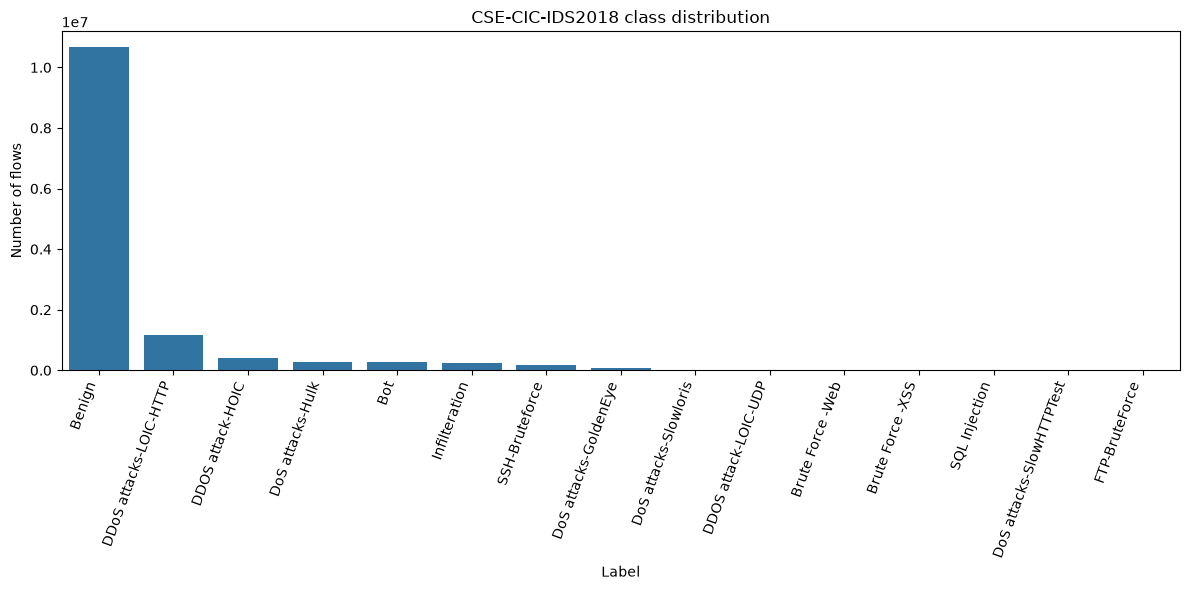

In [10]:
label_counts = df[LABEL_COL].astype(str).str.strip().value_counts()
label_pct = (label_counts / len(df) * 100).round(4)
class_summary = pd.DataFrame({'count': label_counts, 'percentage': label_pct})
display(class_summary)

plt.figure(figsize=(12, 6))
sns.barplot(x=class_summary.index, y=class_summary['count'])
plt.xticks(rotation=70, ha='right')
plt.ylabel('Number of flows')
plt.xlabel('Label')
plt.title('CSE-CIC-IDS2018 class distribution')
plt.tight_layout()
plt.show()


## 4. Clean column names and values

CICFlowMeter CSVs can contain whitespace in headers and numeric fields may contain `Infinity`/`NaN`. We normalize headers, strip label whitespace and convert feature columns to numeric where possible.

In [11]:
df.columns = [re.sub(r'\s+', ' ', str(c).strip()) for c in df.columns]
LABEL_COL = next(c for c in df.columns if c.lower() == 'label')
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()

# Convert all columns except known metadata/label fields to numeric where possible.
protected = {LABEL_COL, '__source_file', 'Timestamp', 'Flow ID', 'Src IP', 'Source IP', 'Dst IP', 'Destination IP'}
   
for col in df.columns:
    if col not in protected:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Replace +/- infinity with NaN.
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
   
print('NaN values after numeric conversion:', int(df.isna().sum().sum()))


NaN values after numeric conversion: 0


## 5. Select model features

For the eventual PCAP integration, the model should depend on traffic-derived features that can also be produced from new flows. We therefore remove direct identifiers and metadata such as IP addresses, Flow ID, timestamp and the source filename.

**Important:** `Dst Port` and `Protocol` are retained because they are flow attributes and can be extracted from network traffic. We also retain them as numeric features rather than treating IP addresses as arbitrary categorical IDs.

In [12]:
DROP_COLUMNS = [
    LABEL_COL,
    '__source_file',
    'Flow ID',
    'Src IP', 'Source IP',
    'Dst IP', 'Destination IP',
    'Timestamp'
]

DROP_COLUMNS = [c for c in DROP_COLUMNS if c in df.columns]
X = df.drop(columns=DROP_COLUMNS).copy()
y_raw = df[LABEL_COL].copy()

# Keep only numeric model features.
X = X.select_dtypes(include=np.number)

print('Removed columns:', DROP_COLUMNS)
print('Number of model features:', X.shape[1])
print('Non-numeric columns excluded from X:', [c for c in df.columns if c not in X.columns and c not in DROP_COLUMNS])

feature_missing = X.isna().mean().sort_values(ascending=False)
display(feature_missing.head(15).to_frame('missing_fraction'))


Removed columns: ['Label', '__source_file']
Number of model features: 77
Non-numeric columns excluded from X: []


,missing_fraction
Protocol,0.0
Flow Duration,0.0
Total Fwd Packets,0.0
Total Backward Packets,0.0
Fwd Packets Length Total,0.0
Bwd Packets Length Total,0.0
Fwd Packet Length Max,0.0
Fwd Packet Length Min,0.0
Fwd Packet Length Mean,0.0
Fwd Packet Length Std,0.0


## 6. Remove unusable features and encode labels

Features that are completely missing contain no information and are removed. Missing values in remaining features will be imputed using statistics learned **only from the training set**.

In [13]:
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print('Removing completely missing features:', all_missing)
    X = X.drop(columns=all_missing)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
class_names = list(label_encoder.classes_)

print('Classes:', class_names)
print('Number of classes:', len(class_names))


Classes: ['Benign', 'Bot', 'Brute Force -Web', 'Brute Force -XSS', 'DDOS attack-HOIC', 'DDOS attack-LOIC-UDP', 'DDoS attacks-LOIC-HTTP', 'DoS attacks-GoldenEye', 'DoS attacks-Hulk', 'DoS attacks-SlowHTTPTest', 'DoS attacks-Slowloris', 'FTP-BruteForce', 'Infilteration', 'SQL Injection', 'SSH-Bruteforce']
Number of classes: 15


## 7. Train/test split

We use a stratified split so every class represented in the data is distributed between training and testing according to its frequency. The test set is held out until model evaluation.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Train:', X_train.shape)
print('Test :', X_test.shape)


Train: (10655251, 77)
Test : (2663813, 77)


In [ ]:
#run this to clear ram and avoid notebook crashing
import gc

# Delete large temporary datasets and structures
if 'df' in globals():
    del df
if 'df_part' in globals():
    del df_part
if 'X' in globals():
    del X
if 'y' in globals():
    del y
if 'y_raw' in globals():
    del y_raw
if 'class_summary' in globals():
    del class_summary
if 'label_counts' in globals():
    del label_counts
if 'label_pct' in globals():
    del label_pct

# Collect any leftover variables that are no longer strictly needed
vars_to_delete = [
    'feature_missing', 
    'all_missing', 
    'col', 
    'i', 
    'label_candidates', 
    'parquet_files', 
    'csv_files', 
    'sample', 
    'DROP_COLUMNS', 
    'LABEL_COL'
]

for var in vars_to_delete:
    if var in globals():
        del globals()[var]

# Run garbage collector
gc.collect()

print("RAM cleared. Kept: X_train, X_test, y_train, y_test.")
print('Train:', X_train.shape)
print('Test :', X_test.shape)

## 8. Preprocessing pipelines

We use training-only imputation to avoid leakage. KNN is distance-based and therefore uses standardization. Random Forest and XGBoost are tree-based and do not require standardization, although they still receive the same missing-value handling.

In [ ]:
import gc
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Downcast training data to float32 to cut memory consumption in half
if 'X_train' in globals():
    X_train = X_train.astype(np.float32)
if 'X_test' in globals():
    X_test = X_test.astype(np.float32)

gc.collect()

# 2. Fit and transform using Imputer
imputer = SimpleImputer(strategy='median', copy=False)  # copy=False performs operation in-place if possible
X_train_imp = imputer.fit_transform(X_train)

# Delete original X_train to free up memory
if 'X_train' in globals():
    del X_train
gc.collect()

X_test_imp = imputer.transform(X_test)
if 'X_test' in globals():
    del X_test
gc.collect()

# 3. Fit and transform using Scaler
scaler = StandardScaler(copy=False)
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

gc.collect()
print('Preprocessed train shape:', X_train_scaled.shape)

In [15]:
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print('Preprocessed train shape:', X_train_imp.shape)


Preprocessed train shape: (10655251, 77)


## 9. Train the three proposed models

These are the models specified in the project proposal:
- **Random Forest**
- **XGBoost**
- **K-nearest neighbors**

The initial parameters below provide a reasonable baseline. Hyperparameter tuning should be performed after establishing these baselines rather than before.

In [18]:
use_cuda = True  # set to False if your machine does not have a CUDA-capable GPU

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_features='sqrt',
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        eval_metric='mlogloss',
        tree_method='gpu_hist' if use_cuda else 'hist',
        predictor='gpu_predictor' if use_cuda else 'auto',
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        n_jobs=-1
    )
}

trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    print(f'\nTraining {name}...')
    if name == 'KNN':
        model.fit(X_train_scaled, y_train)
        pred = model.predict(X_test_scaled)
        proba = model.predict_proba(X_test_scaled)
    else:
        model.fit(X_train_imp, y_train)
        pred = model.predict(X_test_imp)
        proba = model.predict_proba(X_test_imp)
    trained_models[name] = model
    predictions[name] = pred
    probabilities[name] = proba
    print('Done.')



Training Random Forest...


KeyboardInterrupt: 

In [ ]:
# Save the trained models to disk for reuse in later stages
for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    path = OUTPUT_DIR / filename
    joblib.dump(model, path)
    print(f"Saved {name} to {path}")

print("Saved models:", sorted(p.name for p in OUTPUT_DIR.iterdir() if p.suffix == ".joblib"))

## 10. Evaluate model performance

In [ ]:
def multiclass_auc(y_true, proba, n_classes):
    try:
        y_bin = label_binarize(y_true, classes=np.arange(n_classes))
        return roc_auc_score(y_bin, proba, multi_class='ovr', average='weighted')
    except ValueError:
        return np.nan

results = []
for name in models:
    pred = predictions[name]
    proba = probabilities[name]
    cm = confusion_matrix(y_test, pred, labels=np.arange(len(class_names)))

    tn_fp_fn_tp = None
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision_weighted': precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall_weighted': recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1_weighted': f1_score(y_test, pred, average='weighted', zero_division=0),
        'F1_macro': f1_score(y_test, pred, average='macro', zero_division=0),
        'ROC_AUC_weighted_OVR': multiclass_auc(y_test, proba, len(class_names))
    })

results_df = pd.DataFrame(results).set_index('Model').sort_values('F1_macro', ascending=False)
display(results_df)


### Classification reports and confusion matrices

In [ ]:
for name in models:
    print('\n' + '=' * 80)
    print(name)
    print('=' * 80)
    print(classification_report(
        y_test,
        predictions[name],
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions[name], labels=np.arange(len(class_names)))
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix — {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks(rotation=70, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


## 11. Binary benign vs malicious evaluation

Because the project is fundamentally an intrusion detector, we also evaluate the models as a binary detector. This is useful alongside the multiclass attack-category results.

Here, `Benign` is the normal class and every other label is treated as malicious.

In [ ]:
benign_indices = {i for i, label in enumerate(class_names) if label.strip().lower() == 'benign'}
if not benign_indices:
    raise ValueError('Benign label not found.')

benign_idx = next(iter(benign_indices))
y_test_binary = (y_test != benign_idx).astype(int)

binary_results = []
for name in models:
    pred_binary = (predictions[name] != benign_idx).astype(int)
    # Probability of malicious = 1 - probability of benign.
    malicious_proba = 1.0 - probabilities[name][:, benign_idx]
    tn, fp, fn, tp = confusion_matrix(y_test_binary, pred_binary, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    auc = roc_auc_score(y_test_binary, malicious_proba)
    binary_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_binary, pred_binary),
        'Precision': precision_score(y_test_binary, pred_binary, zero_division=0),
        'Recall': recall_score(y_test_binary, pred_binary, zero_division=0),
        'F1': f1_score(y_test_binary, pred_binary, zero_division=0),
        'ROC_AUC': auc,
        'False_Positive_Rate': fpr,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

binary_results_df = pd.DataFrame(binary_results).set_index('Model')
display(binary_results_df)


## 12. Feature importance

Tree-based models can provide an initial indication of which flow features contribute most to classification. This is useful for later integration because the selected features must be reproducible by the PCAP-to-flow extractor.

In [ ]:
for name in ['Random Forest', 'XGBoost']:
    model = trained_models[name]
    importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(20)
    display(importance.to_frame('importance'))

    plt.figure(figsize=(10, 7))
    importance.sort_values().plot(kind='barh')
    plt.title(f'Top 20 Feature Importances — {name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()


## 13. Save models and preprocessing artifacts

These files are important for the next stage. The integration pipeline must use the **same feature order, imputer and scaler** as model training.

In [ ]:
artifacts = {
    'feature_names': list(X.columns),
    'class_names': class_names,
    'label_encoder': label_encoder,
    'imputer': imputer,
    'scaler': scaler,
    'drop_columns': DROP_COLUMNS,
    'random_state': RANDOM_STATE
}

joblib.dump(artifacts, OUTPUT_DIR / 'preprocessing.joblib')
for name, model in trained_models.items():
    filename = name.lower().replace(' ', '_') + '.joblib'
    joblib.dump(model, OUTPUT_DIR / filename)

results_df.to_csv(OUTPUT_DIR / 'multiclass_results.csv')
binary_results_df.to_csv(OUTPUT_DIR / 'binary_results.csv')

print('Saved artifacts:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(' -', p)


## 14. Next stage: PCAP → flow → ML → alert

The next notebook/script should implement the integration requirement from the project proposal:

```text
PCAP
  ↓
CICFlowMeter / compatible flow extractor
  ↓
Flow CSV
  ↓
same feature selection + imputer + scaling
  ↓
trained classifier
  ↓
Benign / attack category
  ↓
IDS-like alert
```

The official CSE-CIC-IDS2018 documentation explicitly notes that the raw captured PCAPs can be used with a new feature extractor, after which the generated features can be used for analysis. citeturn0search0

For the project, this is preferable to building the final system around the pre-generated CSV rows alone because it directly tests the requirement of detecting previously unseen PCAP traffic.